# P2.11 — Ageing and the household-forming ages: do they go with where affordability worsened?

**Questions:** RQ3.5 (how ageing, internal migration and single-person households affected demand). The data give
no single-person split for the years between censuses and no internal-migration flows by age, so this notebook
covers the part they allow: **ageing** (the age structure of residents, 2011 to 2023) and the
**household-forming ages** (25 to 44, the people who rent and buy first homes), against the change of
price-to-income 2016 to 2023 across mainland municipalities.

**Data:** resident population by five-year age group, municipality and year (`ine_population`, 2011 to 2023).
Bands in `analysis/age_structure.py`. The panel regressions of P2.02 already include the share aged 65+ (no robust
association); here the age change enters as a cross-section, next to the foreign-resident change, because the
two overlap: young adults arrive as migrants.

**Reading rule, fixed before looking:** an age variable "matters" for the change in price-to-income if its
coefficient keeps its sign and is below p = 0.05 within district, with coast and density class, and with the
change in the foreign-resident share. Associations, not effects.

In [1]:
import pandas as pd

from pthousing.analysis import age_structure as ag
from pthousing.analysis import supply
from pthousing.data import build_panel, typology
from pthousing.viz import charts, style

style.apply_style()
START, END = 2016, 2023
panel = build_panel.read("panel_municipality_year")
pop = ag.read_population()
counts = ag.band_counts(pop)
shares = ag.band_shares(counts)
ty = typology.read().set_index("muni_code")
ty["coast"] = ty["coast_class"].replace({"estuary": "coast"})
ty["segment"] = ty["coast"] + " / " + ty["density_class"]

## Step 1 — The national picture

In [2]:
nat = ag.national_bands(counts)
cols = [*ag.BANDS, *(f"{b}_pct" for b in ag.BANDS), "population_n"]
national = nat.loc[[2011, 2016, 2023], cols].round(1)
style.save_table(nat[cols].round(2).reset_index(), "p2", "age_bands_national")
print(national[[f"{b}_pct" for b in ag.BANDS]].to_string())
print((national[list(ag.BANDS)] / 1e6).round(3).to_string())

      age_0_14_pct  age_15_24_pct  age_25_44_pct  age_45_64_pct  age_65plus_pct  age_80plus_pct
year                                                                                           
2011          15.0           10.8           28.3           26.7            19.2             5.3
2016          14.0           10.6           26.1           28.0            21.3             6.3
2023          12.8           10.6           25.7           27.9            22.9             6.8
      age_0_14  age_15_24  age_25_44  age_45_64  age_65plus  age_80plus
year                                                                   
2011     1.582      1.136      2.993      2.823       2.025       0.565
2016     1.447      1.098      2.701      2.893       2.206       0.654
2023     1.432      1.191      2.884      3.127       2.570       0.761


## Step 2 — Where is the population oldest, and where did it age most?

In [3]:
change = ag.change_between(
    shares, 2011, END, ["age_65plus_pct", "age_25_44_pct", "ageing_index"]
).join(ty[["segment", "coast", "density_class", "territory"]])
by_segment = (
    change.groupby("segment")
    .agg(
        municipalities_n=("age_65plus_pct_2011", "size"),
        age_65plus_2011=("age_65plus_pct_2011", "median"),
        age_65plus_2023=("age_65plus_pct_2023", "median"),
        age_25_44_2011=("age_25_44_pct_2011", "median"),
        age_25_44_2023=("age_25_44_pct_2023", "median"),
        ageing_index_2023=("ageing_index_2023", "median"),
    )
    .round(1)
    .reset_index()
)
style.save_table(by_segment, "p2", "age_structure_by_class")
by_segment

,segment,municipalities_n,age_65plus_2011,age_65plus_2023,age_25_44_2011,age_25_44_2023,ageing_index_2023
0,coast / intermediate,42,17.8,21.5,29.6,25.3,161.6
1,coast / rural,34,21.8,23.6,27.0,24.6,191.9
2,coast / urban,20,17.0,21.6,29.0,25.8,161.1
3,inland / intermediate,42,19.4,24.1,28.2,24.0,195.0
4,inland / rural,155,26.7,31.7,23.9,20.0,296.4
5,inland / urban,15,13.8,20.5,30.7,26.0,154.2


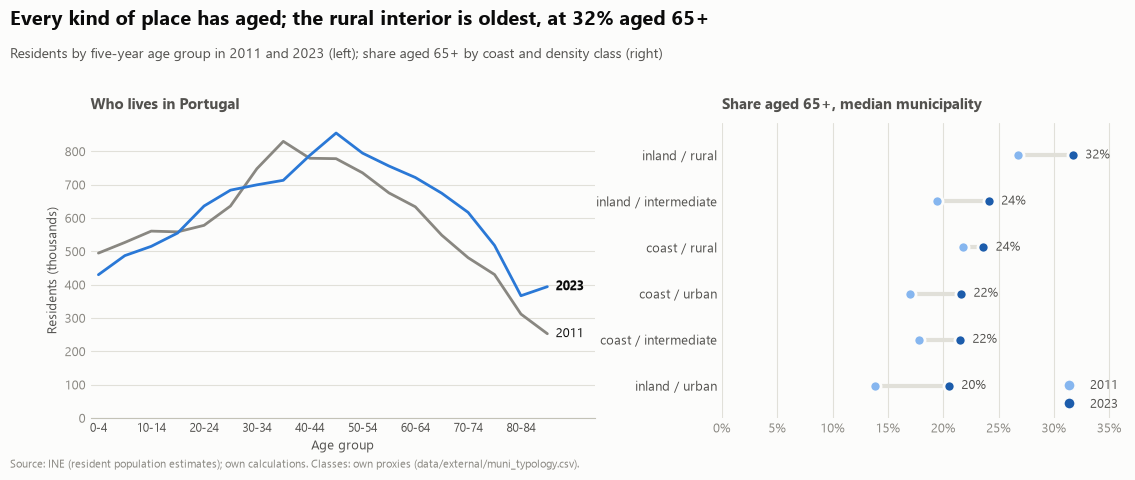

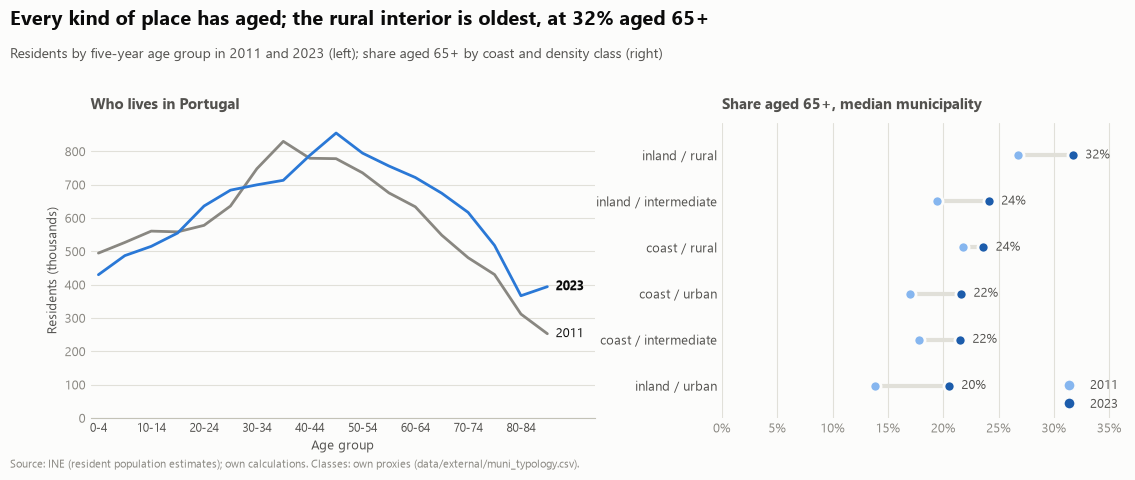

In [4]:
profile = ag.national_profile(pop, [2011, END])
groups = by_segment.assign(
    label=by_segment["segment"],
    start=by_segment["age_65plus_2011"],
    end=by_segment["age_65plus_2023"],
).sort_values("end", ascending=False)
fig = charts.age_structure(profile, groups)
style.save_fig(fig, "p2", "age_structure")
fig

## Step 3 — Age change and price-to-income, 2016 to 2023 (mainland, RQ3.5)
Outcome: log change of price-to-income. Drivers (percentage points, 2016 to 2023): the share aged 25 to 44, the
share aged 65+, and the foreign-resident share of residents. Same-district comparisons, HC3 errors.

In [5]:
d = ag.change_between(shares, START, END, ["age_65plus_pct", "age_25_44_pct"]).join(
    ty[["coast", "density_class", "territory"]]
)
d["dlog_pti"] = supply.pti_change(panel, START, END)
d["district"] = supply.area_of(panel)
foreign = panel.pivot(index="muni_code", columns="year", values="foreign_residents_pct")
d["foreign_change_pp"] = foreign[END] - foreign[START]
d = d[d["territory"] == "continente"]
Y25, O65, F = "age_25_44_pct_change_pp", "age_65plus_pct_change_pp", "foreign_change_pp"
print(d[[Y25, O65, F, "dlog_pti"]].corr().round(2))

                          age_25_44_pct_change_pp  age_65plus_pct_change_pp  \
age_25_44_pct_change_pp                      1.00                     -0.55   
age_65plus_pct_change_pp                    -0.55                      1.00   
foreign_change_pp                            0.58                     -0.47   
dlog_pti                                     0.11                     -0.24   

                          foreign_change_pp  dlog_pti  
age_25_44_pct_change_pp                0.58      0.11  
age_65plus_pct_change_pp              -0.47     -0.24  
foreign_change_pp                      1.00      0.45  
dlog_pti                               0.45      1.00  


In [6]:
GEO = ["coast", "density_class"]
MODELS = {
    "25-44 share, same district": ([Y25], None),
    "25-44 share, + coast and density": ([Y25], GEO),
    "25-44 share, + foreign residents": ([Y25, F], GEO),
    "65+ share, same district": ([O65], None),
    "65+ share, + coast and density": ([O65], GEO),
    "65+ share, + foreign residents": ([O65, F], GEO),
    "Both, + foreign residents": ([Y25, O65, F], GEO),
}
table = pd.concat(
    [
        supply.associations(
            d, "dlog_pti", xs, fixed_effects="district", categorical=cats, label=name
        )
        for name, (xs, cats) in MODELS.items()
    ],
    ignore_index=True,
)
style.save_table(table, "p2", "age_structure_associations")
print(
    table[["spec", "term", "coef", "se", "p", "coef_per_sd", "n_obs"]]
    .round(3)
    .to_string(index=False)
)

                            spec                     term   coef    se     p  coef_per_sd  n_obs
      25-44 share, same district  age_25_44_pct_change_pp  0.013 0.007 0.069        0.024    267
25-44 share, + coast and density  age_25_44_pct_change_pp  0.004 0.007 0.543        0.008    267
25-44 share, + foreign residents  age_25_44_pct_change_pp -0.013 0.009 0.147       -0.024    267
25-44 share, + foreign residents        foreign_change_pp  0.024 0.008 0.002        0.070    267
        65+ share, same district age_65plus_pct_change_pp -0.022 0.011 0.046       -0.048    267
  65+ share, + coast and density age_65plus_pct_change_pp -0.017 0.011 0.111       -0.037    267
  65+ share, + foreign residents age_65plus_pct_change_pp -0.007 0.013 0.594       -0.015    267
  65+ share, + foreign residents        foreign_change_pp  0.016 0.007 0.035        0.045    267
       Both, + foreign residents  age_25_44_pct_change_pp -0.019 0.010 0.054       -0.037    267
       Both, + foreign residen

## Step 4 — Is the young-adult share a migration story?
The change in the 25 to 44 share by third of the foreign-resident change, and the two correlated.

In [7]:
d["foreign_third"] = pd.qcut(d[F], 3, labels=["lowest third", "middle third", "highest third"])
thirds = (
    d.groupby("foreign_third", observed=True)
    .agg(
        municipalities_n=(F, "size"),
        foreign_change_pp=(F, "median"),
        age_25_44_change_pp=(Y25, "median"),
        age_65plus_change_pp=(O65, "median"),
        pti_change_log=("dlog_pti", "median"),
    )
    .round(3)
    .reset_index()
)
style.save_table(thirds, "p2", "age_structure_by_foreign_third")
print("correlation, 25-44 change and foreign-resident change:", round(d[Y25].corr(d[F]), 2))
thirds

correlation, 25-44 change and foreign-resident change: 0.58


,foreign_third,municipalities_n,foreign_change_pp,age_25_44_change_pp,age_65plus_change_pp,pti_change_log
0,lowest third,93,1.027,-1.927,3.651,0.026
1,middle third,92,2.533,-1.423,2.313,0.135
2,highest third,93,5.768,-0.387,1.041,0.362


## Findings

1. **The country aged, and the household-forming pool shrank then recovered.** Residents aged 65+ went from 19.2% (2.02
   million) in 2011 to 22.9% (2.57 million) in 2023, those 80+ from 5.3% to 6.8%, children from 15.0% to 12.8%. People
   aged 25 to 44 fell from 2.99 million (28.3%) to 2.70 million in 2016 and recovered to 2.88 million (25.7%) in 2023.
2. **The rural interior is oldest, the inland towns aged fastest.** Median share aged 65+ in 2023: 31.7% in inland rural
   municipalities (296 people 65+ per 100 children), 20.5% in the 15 inland urban ones, which gained 6.7 points from the lowest base;
   coastal classes 21.5% to 23.6%.
3. **Neither age variable goes with the rise in price-to-income once the foreign-resident change is in (RQ3.5).** The
   25 to 44 share: +1.3% per point (p = 0.07) in the same district, +0.4% (p = 0.54) with coast and density, −1.3%
   (p = 0.15) with the foreign-resident change. The 65+ share: −2.2% (p = 0.046), −1.7% (p = 0.11), −0.7% (p = 0.59).
   The foreign-resident change stays positive (+1.6% to +2.4% per point, p = 0.002 to 0.035). By the reading rule fixed
   in advance, neither age variable matters.
4. **The young-adult share is carried by migrants.** The 25 to 44 share fell 1.9 points in the third of municipalities with
   the least growth in foreign residents and 0.4 in the third with the most; the 65+ share rose 3.7 and 1.0 points; the
   median log rise of price-to-income was 0.03 against 0.36. The correlation of the 25 to 44 change with the
   foreign-resident change is 0.58.

**Limits.** Ages are of residents, so ageing in place cannot be told from the young leaving; no internal-migration flows by
age and no single-person households between censuses; the 65+ share is a poor proxy for who owns or wants to sell; 267
mainland municipalities, one cross-section 2016 to 2023. Associations, not effects.